In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Cargar desde URL
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
columnas = ['Embarazos', 'Glucosa', 'Presion', 'Piel', 'Insulina', 'IMC', 'Pedigree', 'Edad', 'Clase']
diabetes = pd.read_csv(url, names=columnas)

In [4]:
diabetes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Embarazos  768 non-null    int64  
 1   Glucosa    768 non-null    int64  
 2   Presion    768 non-null    int64  
 3   Piel       768 non-null    int64  
 4   Insulina   768 non-null    int64  
 5   IMC        768 non-null    float64
 6   Pedigree   768 non-null    float64
 7   Edad       768 non-null    int64  
 8   Clase      768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [5]:
diabetes.describe()

,Embarazos,Glucosa,Presion,Piel,Insulina,IMC,Pedigree,Edad,Clase
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [6]:
diabetes.head(10)

,Embarazos,Glucosa,Presion,Piel,Insulina,IMC,Pedigree,Edad,Clase
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


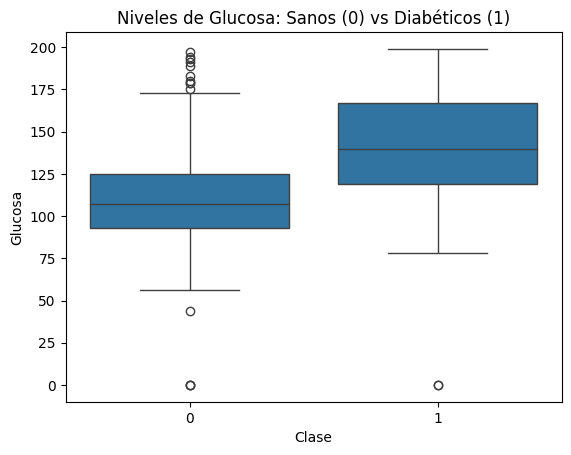

In [9]:
# Visualizar
sns.boxplot(x='Clase', y='Glucosa', data=diabetes)
plt.title("Niveles de Glucosa: Sanos (0) vs Diabéticos (1)")
plt.show()

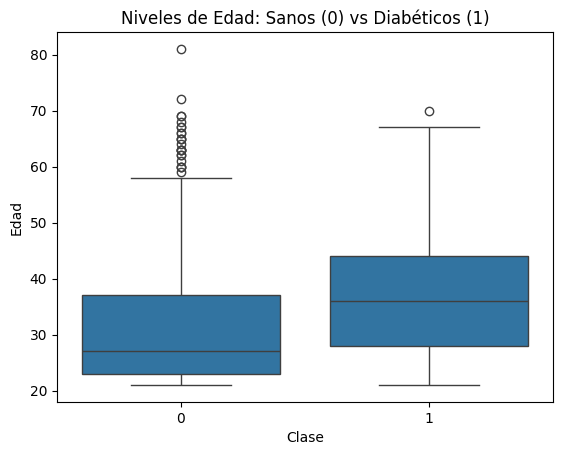

In [11]:
# Visualizar
sns.boxplot(x='Clase', y='Edad', data=diabetes)
plt.title("Niveles de Edad: Sanos (0) vs Diabéticos (1)")
plt.show()

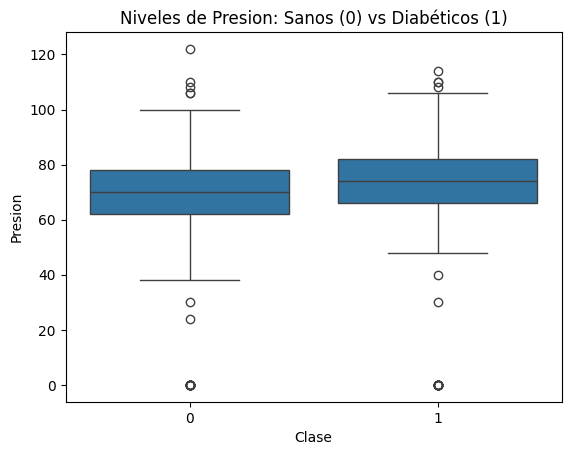

In [10]:
# Visualizar
sns.boxplot(x='Clase', y='Presion', data=diabetes)
plt.title("Niveles de Presion: Sanos (0) vs Diabéticos (1)")
plt.show()

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

X = diabetes.drop('Clase', axis=1)
y = diabetes['Clase']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Entrenar (aumentamos iteraciones para que converja bien)
modelo_diabetes = LogisticRegression(max_iter=1000)
modelo_diabetes.fit(X_train, y_train)

# Ver coeficientes
coefs = pd.DataFrame(modelo_diabetes.coef_[0], X.columns, columns=['Peso'])
print(coefs.sort_values(by='Peso', ascending=False))

               Peso
Pedigree   0.626741
IMC        0.102607
Embarazos  0.064376
Edad       0.037096
Glucosa    0.034095
Piel       0.003292
Insulina  -0.001804
Presion   -0.013879


C:\Users\magal\AppData\Local\Temp\ipykernel_17348\226558731.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Coeficiente', y='Variable', data=coefs_2, palette='viridis')


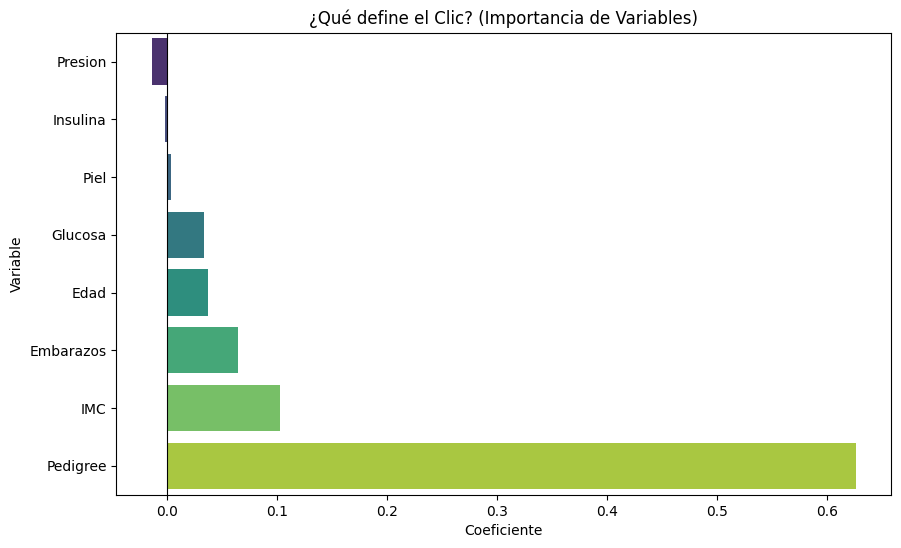

In [16]:
coefs_2 = pd.DataFrame({'Variable': X.columns, 'Coeficiente': modelo_diabetes.coef_[0]})
coefs_2 = coefs_2.sort_values(by='Coeficiente')


# Graficar
plt.figure(figsize=(10, 6))
sns.barplot(x='Coeficiente', y='Variable', data=coefs_2, palette='viridis')
plt.axvline(0, color='black', linewidth=0.8) # Línea central
plt.title('¿Qué define el Clic? (Importancia de Variables)')
plt.show()

In [20]:
# Predecir probabilidad para los primeros 10 pacientes del test
# La columna de la derecha [:, 1] es la probabilidad de "Tener Diabetes"
probs = modelo_diabetes.predict_proba(X_test)[:20, 1]
clases_reales = y_test[:20].values

for p, real in zip(probs, clases_reales):
    print(f"Probabilidad: {p:.2%} -> Realidad: {'Diabético' if real==1 else 'Sano'}")

Probabilidad: 27.59% -> Realidad: Sano
Probabilidad: 18.84% -> Realidad: Sano
Probabilidad: 11.45% -> Realidad: Sano
Probabilidad: 16.35% -> Realidad: Sano
Probabilidad: 47.15% -> Realidad: Sano
Probabilidad: 44.18% -> Realidad: Sano
Probabilidad: 1.55% -> Realidad: Sano
Probabilidad: 66.08% -> Realidad: Sano
Probabilidad: 54.15% -> Realidad: Sano
Probabilidad: 77.73% -> Realidad: Sano
Probabilidad: 25.59% -> Realidad: Diabético
Probabilidad: 89.73% -> Realidad: Sano
Probabilidad: 33.62% -> Realidad: Diabético
Probabilidad: 30.30% -> Realidad: Sano
Probabilidad: 8.20% -> Realidad: Sano
Probabilidad: 38.09% -> Realidad: Diabético
Probabilidad: 13.94% -> Realidad: Sano
Probabilidad: 7.48% -> Realidad: Sano
Probabilidad: 86.67% -> Realidad: Diabético
Probabilidad: 56.14% -> Realidad: Diabético


C:\Users\magal\AppData\Local\Temp\ipykernel_17348\1650834326.py:33: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  plt.axvline(corte_x, color='green', linestyle=':', label=f'Frontera ({float(corte_x):.1f} u)')


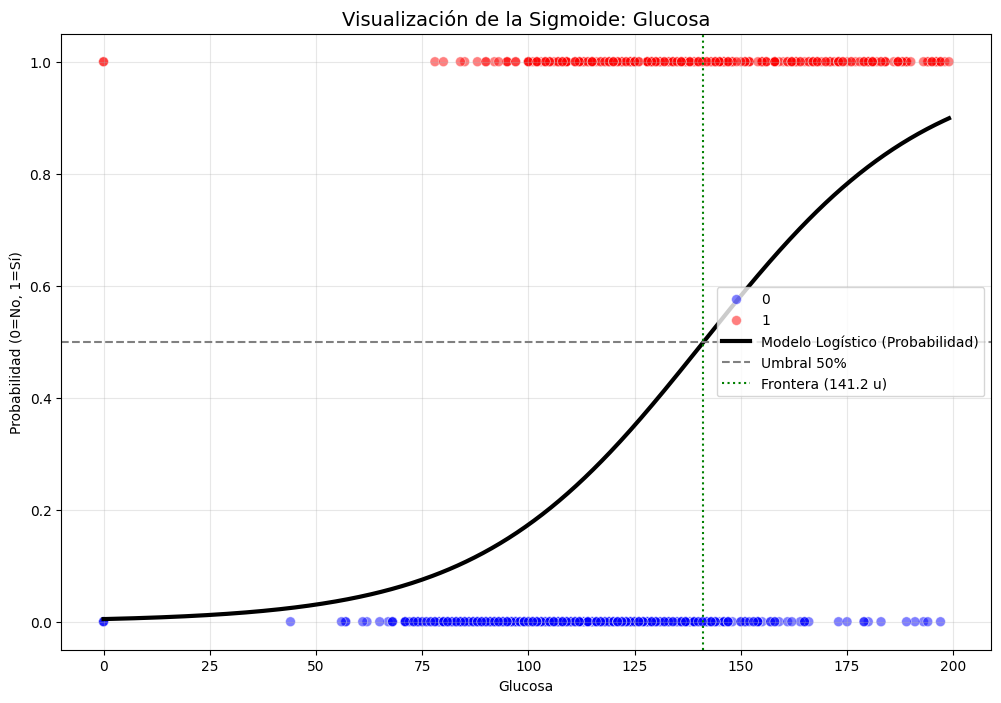

In [26]:
import numpy as np
from scipy.special import expit # Función sigmoide matemática

# --- Preparación para visualización 2D ---
# Elegimos la variable más fuerte: 'Daily Time Spent on Site'
feature_col = 'Glucosa'
X_simple = diabetes[[feature_col]]
y_simple = diabetes['Clase']

# Entrenar modelo simple auxiliar (solo para este gráfico)
model_viz = LogisticRegression()
model_viz.fit(X_simple, y_simple)

# Generar puntos para la línea suave
x_range = np.linspace(X_simple.min(), X_simple.max(), 500)
y_sigmoid = expit(x_range * model_viz.coef_[0][0] + model_viz.intercept_[0])

# --- Graficar ---
plt.figure(figsize=(12, 8))

# A) Puntos Reales
sns.scatterplot(x=feature_col, y='Clase', data=diabetes, 
                hue='Clase', palette={0: 'blue', 1: 'red'}, 
                s=50, alpha=0.5)

# B) Curva Sigmoide
plt.plot(x_range, y_sigmoid, color='black', linewidth=3, label='Modelo Logístico (Probabilidad)')

# C) Líneas de referencia
plt.axhline(0.5, color='gray', linestyle='--', label='Umbral 50%')
# Calcular punto de corte visual
corte_x = x_range[np.abs(y_sigmoid - 0.5).argmin()]
plt.axvline(corte_x, color='green', linestyle=':', label=f'Frontera ({float(corte_x):.1f} u)')

plt.title(f'Visualización de la Sigmoide: {feature_col}', fontsize=14)
plt.ylabel('Probabilidad (0=No, 1=Sí)')
plt.legend(loc='center right')
plt.grid(True, alpha=0.3)
plt.show()